In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Image Classification Data

Softmax regression, as that section described it, is ready to be
trained, but it needs labeled examples to learn from. Our examples will be
images, and the choice of dataset decides what our experiments can show.
Which dataset should we use? A good dataset for this book is hard enough that
a better model scores visibly higher, and small enough that a model trains in
minutes inside a notebook.

The two best-known image datasets each meet only one of these needs.
MNIST [@LeCun.Bottou.Bengio.ea.1998], 70,000 grayscale images of
handwritten digits with $28 \times 28$ pixels in 10 classes, is small but too
easy. Convolutional networks classify more than 99% of its test digits
correctly, and even classical methods reach about 97%, so models that differ
in kind differ in accuracy by a few points at most.
ImageNet [@Deng.Dong.Socher.ea.2009], with 1.2 million color images in
1,000 classes, separates models well, but training a network on it takes
hours to days of GPU time.

Fashion-MNIST [@Xiao.Rasul.Vollgraf.2017] lies between the two. It keeps
the format of MNIST, 70,000 grayscale images of $28 \times 28$ pixels in 10
classes, but shows garments instead of digits, and its classes are harder to
tell apart: a shirt can look like a T-shirt, a pullover, or a coat. Linear
classifiers reach about 83% accuracy on it and good convolutional networks
more than 90%, which leaves room to tell models apart. We use it for the rest of
this chapter and for much of the book.

This section loads Fashion-MNIST in each framework, reads it in minibatches,
checks the shape of what the loader delivers, and looks at a few images
before any model touches them. Every later classifier in the book reads its
data through the class we write here.

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

In [ ]:
import tensorflow as tf
import time

In [ ]:
d2l.use_svg_display()

## Loading the Dataset

Fashion-MNIST has 7,000 images in each of its 10 classes: t-shirt, trouser,
pullover, dress, coat, sandal, shirt, sneaker, bag, and ankle boot. Its
authors split them into 60,000 training and 10,000 test images, 6,000 and
1,000 per class. Each pixel stores a brightness between 0 and 255, with the
background at 0.

As in that section, a `DataModule` holds the data and hands
minibatches to the `Trainer` through its methods `train_dataloader` and
`val_dataloader`. The class `FashionMNIST` downloads the dataset on first use
and keeps both splits in memory. It has two hyperparameters: `batch_size`,
the number of examples per minibatch, and `resize`, the height and width of
the images that the loader delivers. The images keep their native $28 \times 28$ pixels by default;
networks in later chapters that are built for larger inputs ask for
enlarged images instead.
<!-- d2l:prose id=image-classification-dataset-md-3 fw=tensorflow, jax -->

Keras downloads Fashion-MNIST and returns each split as a pair of NumPy
arrays, images and labels. The loader below converts them.

In [2]:
class FashionMNIST(d2l.DataModule):
    """The Fashion-MNIST dataset."""
    def __init__(self, batch_size=64, resize=(28, 28)):
        super().__init__()
        self.save_hyperparameters()
        self.train, self.val = tf.keras.datasets.fashion_mnist.load_data()

We load the dataset and count the images in each split.

In [3]:
data = FashionMNIST()
len(data.train[0]), len(data.val[0])

(60000, 10000)

Fashion-MNIST has no validation split of its own, so the 10,000 test images
serve as our validation data: the `Trainer` reports the loss on them after
every epoch. A test set that we consult again and again while we compare
models stops being an unbiased test of the model we finally choose;
that section measures how much this costs.

The labels are class indices from 0 to 9. To read them, we map each index
to the name of its class.

In [4]:
@d2l.add_to_class(FashionMNIST)
def text_labels(self, indices):
    """Return text labels."""
    labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
              'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
    return [labels[int(i)] for i in indices]

## Reading Minibatches

The loader for the training split draws the examples in a new random order
in every epoch, so that the minibatches differ from epoch to epoch; the
loader for the validation split reads them in their stored order. Both
convert the pixel values from integers between 0 and 255 into floating-point
numbers between 0 and 1, and resize the images if asked to.

With minibatches of 64, the 60,000 training images make 937 full
minibatches and a last, incomplete one of 32 images
(60,000 = 937 $\times$ 64 + 32). Both loaders keep that last minibatch, so
that every epoch trains on every training image and the validation loss
covers every test image (10,000 = 156 $\times$ 64 + 16). Because the order
changes, a different set of 32 images lands in the short minibatch in each
epoch. Dropping it instead, an option every framework's loader offers, would
give every step the same shape at the price of leaving 32 images out of each
epoch.

JAX has no loader for image datasets, so we build a pipeline with
TensorFlow's `tf.data`: it adds a channel axis to the images, scales them
to $[0, 1]$, pairs them with the labels, shuffles them with a buffer that
holds all training examples (a uniformly random order, drawn anew on every
pass), groups them into minibatches, and resizes each minibatch. The class
`TensorFlowDataLoader` wraps the pipeline: iterating over it yields each
minibatch as NumPy arrays, which JAX functions accept, and `len` gives the
number of minibatches. The `Trainer` compiles its training step once for
the full minibatches and once more for the shorter last one, since JAX
compiles a function anew for each input shape.

In [5]:
class TensorFlowDataLoader:
    """Expose a tf.data.Dataset as re-iterable NumPy batches."""
    def __init__(self, dataset):
        self.dataset = dataset

    def __iter__(self):
        return self.dataset.as_numpy_iterator()

    def __len__(self):
        return len(self.dataset)

In [6]:
@d2l.add_to_class(FashionMNIST)
def get_dataloader(self, train):
    X, y = self.train if train else self.val
    X = tf.expand_dims(X, axis=3) / 255  # Channel axis last; values in [0, 1]
    resize = lambda X, y: (tf.image.resize(X, self.resize), y)
    return TensorFlowDataLoader(tf.data.Dataset.from_tensor_slices(
        (X, tf.cast(y, tf.int32))).shuffle(len(y) if train else 1).batch(
            self.batch_size).map(resize))

An image is a three-dimensional tensor: a number of *channels* $c$, one for
each color, and the height $h$ and width $w$ of the image in pixels. Here
$c = 1$ because the images are grayscale; color photographs have $c = 3$.
Frameworks disagree on where the channel axis goes: *channel-first* layout
stores an image as $c \times h \times w$, *channel-last* layout as
$h \times w \times c$. We read one minibatch and look at the shape of its
first image.

In [7]:
X, y = next(iter(data.train_dataloader()))
X[0].shape  # Channel-last: (height, width, channels)

(28, 28, 1)

A minibatch adds an axis for the examples in front, and its labels form a
vector with one entry per example.

In [8]:
print(X.shape, X.dtype, y.shape, y.dtype)

(64, 28, 28, 1) float32 (64,) int32


The images arrive as 32-bit floats and the labels as integers. One minibatch
of images takes $64 \times 784 \times 4$ bytes, about 200 KB, and the whole
training set as floats about 190 MB.

A loader that is slower than the model leaves the processor waiting for data.
We time one pass over the training set without any model.

In [9]:
tic = time.time()
for X, y in data.train_dataloader():
    continue
f'{time.time() - tic:.2f} sec'

'0.66 sec'

The time depends on the storage, the number of loader workers, the
framework, and the hardware, so the number above holds only for the machine
that ran this notebook. It is the least time that an epoch of training can
take. When we train models in the following sections, compare it with the
time per epoch: if the two are close, loading limits training, and more
loader workers or prefetching of the next minibatches help.

## Inspecting the Images

We look at the data before we train on it. A look catches errors that no
loss curve reveals: labels attached to the wrong images, images flipped or
transposed, a channel axis in the wrong place. The method `visualize` shows
the images of a minibatch, each titled with its label. It calls the library
function `d2l.show_images`, which lays out a list of images in a grid with
optional titles. Matplotlib would draw single-channel images in false
color, so `visualize` sets the gray color map. Since every image has a
single channel, reshaping removes the channel axis in either layout.

In [10]:
@d2l.add_to_class(FashionMNIST)
def visualize(self, batch, nrows=1, ncols=8, labels=None):
    """Show the images of a batch in grayscale, titled by their labels."""
    X, y = batch
    if labels is None:
        labels = self.text_labels(y)
    X = d2l.reshape(X, (-1, *self.resize))  # Drop the channel axis
    d2l.show_images(X, nrows, ncols, titles=labels, cmap='gray')

Here are the first 16 images of the validation set, which the validation
loader always delivers in the same order.

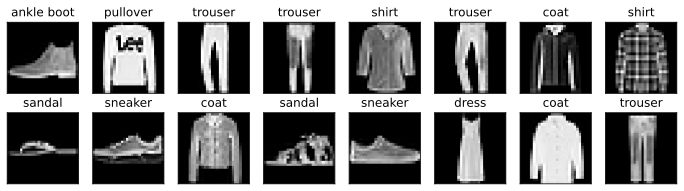

In [11]:
batch = next(iter(data.val_dataloader()))
data.visualize(batch, nrows=2)

The labels match the garments, the garments are upright, and the
background is dark, as stored. Some garments of different classes look
alike: the shirts and the coats above differ in details that
$28 \times 28$ pixels barely resolve. Classes like these are where a
classifier will make most of its mistakes.

We can now load Fashion-MNIST in minibatches in each of the four
frameworks, with the same images and labels in each. To compare classifiers
on it we still need to say how to measure them, which is the subject of the
next section.

## Summary

Fashion-MNIST has 60,000 training and 10,000 test images of garments in 10
classes, grayscale with $28 \times 28$ pixels. It is small enough to train
on in minutes, and hard enough that better models score visibly higher,
unlike MNIST. The class `FashionMNIST` loads the published files, and its
loaders deliver images as floats in $[0, 1]$ and labels as class indices;
the training loader reshuffles every epoch, and both loaders keep the last,
incomplete minibatch. A minibatch of images is a four-dimensional tensor,
with one axis each for the examples, the channels, the height, and the
width. Before training, we look at the images
with their labels, and we check that loading an epoch takes less time than
training on it.

## Exercises

1. [code] **Throughput versus batch size.** Time one full pass of
   `train_dataloader` over the training set for `FashionMNIST` constructed
   with `batch_size` of 1, 16, 64, 256, and 1024, and count the images
   that each pass delivers. Plot throughput (images per second) against
   `batch_size` and explain the shape of the curve in terms of per-batch
   overhead and per-image work.

1. **Shuffling and validation.** `get_dataloader` reshuffles the training
   split every epoch and reads the validation split in the same order every
   epoch. Suppose the validation loader, with the default `batch_size=64`,
   were reshuffled every epoch as well.
    1. Explain whether the validation loss and accuracy, averaged over all
       10,000 validation examples, would change.
    1. The `Trainer` weights each validation batch by its number of
       examples. Suppose it took the unweighted mean of the per-batch
       values instead. Explain whether that mean would change.
    1. Explain whether the images that `visualize` shows for the first
       validation batch would change.

3. [code] **Parallel loading.** The `tf.data` pipeline in `get_dataloader`
   does not use the `num_workers` attribute of `DataModule`; its
   parallelism is set per stage. Time one pass of `train_dataloader` as
   written, then with `num_parallel_calls=tf.data.AUTOTUNE` in the `map`
   call and a trailing `.prefetch(tf.data.AUTOTUNE)`. State under what
   conditions additional parallelism stops helping.

4. [code] **Reshaping versus transposing.** `visualize` removes the
   channel axis with a reshape, which is correct only because $c = 1$.
    1. A minibatch of color images has shape $(n, 3, h, w)$ in channel-first
       layout. Show that reshaping it to $(n, h, w, 3)$ does not move the
       channel axis to the end, by computing which stored value lands at
       position $(0, 0, 0, 1)$ of the result.
    1. Write the transposition that converts it correctly, apply both
       versions to a minibatch of 8 random arrays of shape $(3, 4, 5)$, and
       check which one agrees with indexing the original array.

1. [code] **Upsampling and linear models.** ● Treat the resizing from
   $28 \times 28$ to $32 \times 32$ as a linear map
   $\mathbf{x}' = \mathbf{A}\mathbf{x}$ from the 784 original pixels to the
   1024 resized ones, where the columns of
   $\mathbf{A} \in \mathbb{R}^{1024 \times 784}$ are linearly independent.
    1. Show that softmax regression on $\mathbf{x}'$ can represent exactly
       the classifiers that softmax regression on $\mathbf{x}$ can.
    1. After that section, train `SoftmaxRegressionScratch`
       on data from `FashionMNIST()` and from
       `FashionMNIST(resize=(32, 32))`, with `num_inputs` set to the number
       of pixels per image. Compare the validation accuracies and explain
       any difference in light of the previous part.

1. [extended] **Loader or compute.** ● Combine the two sweeps of problems
   1 and
   3 into a grid
   of batch sizes and loader-parallelism settings, and measure loader
   throughput in images per second at each point. After
   that section, measure the throughput of a full training
   step of `SoftmaxRegressionScratch` (forward pass, loss, gradient, and
   parameter update) on a minibatch held in memory, at the same batch sizes.
   Draw a heatmap of the ratio of loader throughput to training throughput
   over the grid. Identify the region of the grid in which loading is the
   bottleneck, and state whether a crossover exists on your hardware.

[Discussions](https://d2l.discourse.group/t/17980)